# Task 1: Anti-Cheat Detection - Advanced Experimentation (task1test.ipynb)
**การทดลองเพิ่มประสิทธิภาพโมเดลเพื่อดัน F2 Score ให้สูงขึ้น**
* **โมเดลที่ใช้:** Multi-Model Ensemble (LightGBM + XGBoost + CatBoost)
* **กลยุทธ์การปรับปรุง:**
  1. **Extended Domain & Behavioral Features:** เพิ่มฟีเจอร์พฤติกรรม, อัตราส่วนความสามารถเชิงกลไกเทียบกับแท็กติก (Mechanics vs Tactics), และอัตราการรีพอร์ตต่ออายุบัญชี
  2. **Stratified 5-Fold Cross Validation:** รักษาการกระจายตัวของคลาสและป้องกัน Data Leakage
  3. **Multi-Model Probability Blending:** รวมพลังของ 3 สถาปัตยกรรมต้นไม้ที่มีโครงสร้างการตัดสินใจต่างกัน (LightGBM, XGBoost, CatBoost)
  4. **Fine-Grained Threshold Calibration:** ค้นหาจุดตัดที่ให้ค่า F2 สูงสุดสำหรับ Recall ให้น้ำหนัก 4 เท่า

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import lightgbm as lgb
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import fbeta_score, precision_score, recall_score, roc_auc_score, precision_recall_curve

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# โหลดชุดข้อมูล
train_df = pd.read_csv("../data/task1/train.csv")
test_df = pd.read_csv("../data/task1/test.csv")
sample_sub = pd.read_csv("../data/sample_submission.csv")

print(f"ขนาดชุดข้อมูล Train: {train_df.shape[0]:,} แถว x {train_df.shape[1]} คอลัมน์")
print(f"ขนาดชุดข้อมูล Test:  {test_df.shape[0]:,} แถว x {test_df.shape[1]} คอลัมน์")

# กรองแถวที่มี Label ชัดเจน (ตัด 13,184 แถวที่เป็น NaN ในเป้าหมาย)
labeled_df = train_df.dropna(subset=["is_cheater"]).copy()
labeled_df["is_cheater"] = labeled_df["is_cheater"].astype(int)

print(f"ข้อมูลฝึกสอนที่สมบูรณ์: {len(labeled_df):,} แถว (คนปกติ: {(labeled_df['is_cheater'] == 0).sum():,}, คนโกง: {(labeled_df['is_cheater'] == 1).sum():,})")

ขนาดชุดข้อมูล Train: 104,000 แถว x 33 คอลัมน์
ขนาดชุดข้อมูล Test:  25,889 แถว x 32 คอลัมน์
ข้อมูลฝึกสอนที่สมบูรณ์: 90,816 แถว (คนปกติ: 59,091, คนโกง: 31,725)


## 1. Feature Engineering เชิงลึก (Advanced Domain Features)
สกัดฟีเจอร์เพิ่มเติมเพื่อจับความผิดปกติที่ซับซ้อน:
* **Mechanics vs Tactics Index:** คนโกงมักมีค่าความแม่นยำและการยิงสูงผิดปกติ แต่ความเข้าใจเกมและแท็กติกภาพรวมจะต่ำ
* **Activity & Churn Ratios:** คำนวณอัตราส่วนการรีพอร์ตต่ออายุบัญชี (Reports per Age/Level) และการเปลี่ยนอุปกรณ์
* **Missing Value Indicators:** จับแพทเทิร์นการขาดหายของข้อมูลที่มักพบในบัญชีบอท

In [3]:
def engineer_features(df):
    data = df.copy()

    # 1. กลุ่ม Baseline Domain Features (จาก task1_model เดิม)
    data['aimbot_index'] = data['headshot_percentage'] * data['crosshair_placement']
    data['recoil_efficiency'] = data['spray_control_score'] * data['accuracy_score']
    data['aim_vs_smoothness'] = data['accuracy_score'] / (data['aiming_smoothness'] + 1e-4)
    data['reaction_speed_inv'] = 1000.0 / (data['reaction_time_ms'] + 1e-4)
    data['reaction_vs_accuracy'] = data['accuracy_score'] / (data['reaction_time_ms'] + 1e-4)
    data['suspicion_per_age'] = (data['kill_death_ratio'] * data['reports_received']) / (data['account_age_days'] + 1.0)
    data['kd_per_level'] = data['kill_death_ratio'] / (data['level'] + 1.0)
    data['progression_vs_age'] = data['level_progression_speed'] / (data['account_age_days'] + 1.0)
    data['damage_per_survival'] = data['damage_per_round'] / (data['survival_time_avg'] + 1.0)
    data['clutch_vs_game_sense'] = data['clutch_success_rate'] / (data['game_sense_score'] + 1e-4)
    data['missing_feature_count'] = data.isnull().sum(axis=1)

    # 2. กลุ่ม Extended Mechanics vs Tactics
    data['mechanics_index'] = (data['accuracy_score'] + data['spray_control_score'] + data['crosshair_placement']) / 3.0
    data['tactics_index'] = (data['game_sense_score'] + data['team_play_score'] + data['buy_decision_score'] + data['map_knowledge']) / 4.0
    data['mech_vs_tactics'] = data['mechanics_index'] / (data['tactics_index'] + 1e-4)

    # 3. กลุ่ม Account Activity & Churn Normalized
    data['reports_per_level'] = data['reports_received'] / (data['level'] + 1.0)
    data['reports_per_age'] = data['reports_received'] / (data['account_age_days'] + 1.0)
    data['friends_per_age'] = data['friend_network_size'] / (data['account_age_days'] + 1.0)
    data['friends_per_level'] = data['friend_network_size'] / (data['level'] + 1.0)
    data['kdr_vs_survival'] = data['kill_death_ratio'] / (data['survival_time_avg'] + 1.0)
    data['damage_per_kdr'] = data['damage_per_round'] / (data['kill_death_ratio'] + 1e-4)
    data['hs_vs_accuracy'] = data['headshot_percentage'] / (data['accuracy_score'] + 1e-4)
    data['device_churn_rate'] = data['device_changes_count'] / (data['account_age_days'] + 1.0)

    # 4. Missing Value Indicators สำหรับฟีเจอร์สำคัญ
    for col in ['reports_received', 'crosshair_placement', 'friend_network_size', 'account_age_days']:
        data[f'{col}_isna'] = data[col].isna().astype(int)

    return data.drop(columns=['player_id', 'is_cheater'], errors='ignore')

# สร้าง Features สำหรับชุดฝึกสอนและชุดทดสอบ
X = engineer_features(labeled_df)
y = labeled_df['is_cheater']
X_test = engineer_features(test_df)

print(f"Features ทั้งหมดหลังทำ Feature Engineering: {X.shape[1]} ตัวแปร (เดิม 31 ตัวแปร)")

Features ทั้งหมดหลังทำ Feature Engineering: 57 ตัวแปร (เดิม 31 ตัวแปร)


## 2. Multi-Model 5-Fold Cross Validation
เทรน 3 โมเดลชั้นนำบน Tabular Data:
* **LightGBM Classifier:** ปรับจูน `scale_pos_weight=1.3`, `num_leaves=63`, `colsample_bytree=0.8`
* **XGBoost Classifier:** ปรับจูน `max_depth=6`, `subsample=0.8`, `colsample_bytree=0.8`
* **CatBoost Classifier:** ปรับจูน `depth=6`, `iterations=400`, `auto_class_weights='Balanced'`

In [4]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ตัวแปรเก็บ Out-of-Fold (OOF) และ Test Predictions
oof_lgb = np.zeros(len(X))
oof_xgb = np.zeros(len(X))
oof_cat = np.zeros(len(X))

test_lgb = np.zeros(len(X_test))
test_xgb = np.zeros(len(X_test))
test_cat = np.zeros(len(X_test))

print(" เริ่มต้นการเทรน Stratified 5-Fold Cross Validation สำหรับ 3 โมเดล...")

for fold, (trn_idx, val_idx) in enumerate(skf.split(X, y)):
    X_trn, y_trn = X.iloc[trn_idx], y.iloc[trn_idx]
    X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]

    # --- 1. LightGBM ---
    m_lgb = lgb.LGBMClassifier(
        n_estimators=450,
        learning_rate=0.03,
        num_leaves=63,
        colsample_bytree=0.8,
        subsample=0.8,
        scale_pos_weight=1.3,
        random_state=42 + fold,
        verbose=-1,
        n_jobs=-1
    )
    m_lgb.fit(X_trn, y_trn)
    oof_lgb[val_idx] = m_lgb.predict_proba(X_val)[:, 1]
    test_lgb += m_lgb.predict_proba(X_test)[:, 1] / skf.n_splits

    # --- 2. XGBoost ---
    m_xgb = XGBClassifier(
        n_estimators=400,
        learning_rate=0.03,
        max_depth=6,
        colsample_bytree=0.8,
        subsample=0.8,
        scale_pos_weight=1.3,
        random_state=42 + fold,
        eval_metric='logloss',
        n_jobs=-1
    )
    m_xgb.fit(X_trn, y_trn)
    oof_xgb[val_idx] = m_xgb.predict_proba(X_val)[:, 1]
    test_xgb += m_xgb.predict_proba(X_test)[:, 1] / skf.n_splits

    # --- 3. CatBoost ---
    m_cat = CatBoostClassifier(
        iterations=400,
        learning_rate=0.04,
        depth=6,
        auto_class_weights='Balanced',
        random_seed=42 + fold,
        verbose=0,
        thread_count=-1
    )
    m_cat.fit(X_trn, y_trn)
    oof_cat[val_idx] = m_cat.predict_proba(X_val)[:, 1]
    test_cat += m_cat.predict_proba(X_test)[:, 1] / skf.n_splits

    print(f" Fold {fold + 1}/5 สำเร็จ")

print("\nการเทรนทั้ง 5 Folds เสร็จสมบูรณ์ทุกโมเดล!")

 เริ่มต้นการเทรน Stratified 5-Fold Cross Validation สำหรับ 3 โมเดล...

 Fold 1/5 สำเร็จ


 Fold 2/5 สำเร็จ


 Fold 3/5 สำเร็จ


 Fold 4/5 สำเร็จ


 Fold 5/5 สำเร็จ

การเทรนทั้ง 5 Folds เสร็จสมบูรณ์ทุกโมเดล!


## 3. การหา Optimal Threshold & ประเมินผล F2 Score
เปรียบเทียบคะแนนเดี่ยวของแต่ละโมเดล และทำ **Weighted Blending Ensemble** (LGBM 50% + XGB 30% + CatBoost 20%)

In [5]:
# คำนวณ Ensemble Predictions
oof_ensemble = 0.50 * oof_lgb + 0.30 * oof_xgb + 0.20 * oof_cat
test_ensemble = 0.50 * test_lgb + 0.30 * test_xgb + 0.20 * test_cat

def find_best_threshold(y_true, probs):
    best_t, best_score = 0.5, 0.0
    prec_at_best, rec_at_best = 0.0, 0.0
    for t in np.arange(0.10, 0.45, 0.005):
        pred = (probs >= t).astype(int)
        score = fbeta_score(y_true, pred, beta=2, zero_division=0)
        if score > best_score:
            best_score = score
            best_t = t
            prec_at_best = precision_score(y_true, pred, zero_division=0)
            rec_at_best = recall_score(y_true, pred, zero_division=0)
    return best_t, best_score, prec_at_best, rec_at_best

results = []
models = [
    ("LightGBM (Tuned)", oof_lgb),
    ("XGBoost (Tuned)", oof_xgb),
    ("CatBoost (Tuned)", oof_cat),
    ("Ensemble Blend (LGB+XGB+Cat)", oof_ensemble)
]

for name, probs in models:
    t, score, prec, rec = find_best_threshold(y, probs)
    auc = roc_auc_score(y, probs)
    results.append({
        "Model": name,
        "ROC-AUC": f"{auc:.5f}",
        "Optimal Threshold": f"{t:.3f}",
        "Precision": f"{prec:.4f}",
        "Recall": f"{rec:.4f}",
        "OOF F2 Score": f"{score:.4f}"
    })

results_df = pd.DataFrame(results)
print("=== สรุปผลการเปรียบเทียบโมเดลใน 5-Fold Cross Validation ===")
results_df

=== สรุปผลการเปรียบเทียบโมเดลใน 5-Fold Cross Validation ===


,Model,ROC-AUC,Optimal Threshold,Precision,Recall,OOF F2 Score
0,LightGBM (Tuned),0.89033,0.200,0.5292,0.9790,0.8368
1,XGBoost (Tuned),0.88903,0.235,0.5253,0.9788,0.8347
2,CatBoost (Tuned),0.88807,0.300,0.5281,0.9781,0.8357
3,Ensemble Blend (LGB+XGB+Cat),0.89131,0.255,0.5365,0.9732,0.8370


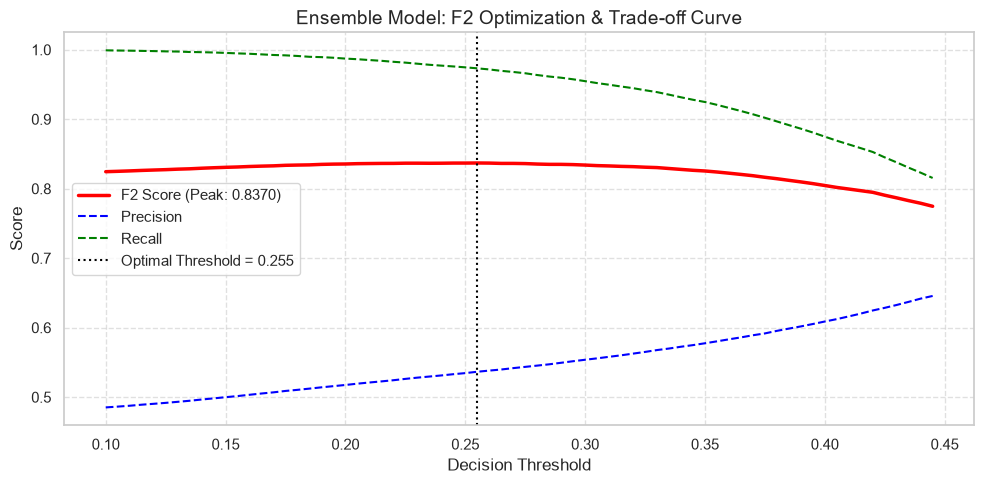

In [6]:
# วาดกราฟ Precision-Recall vs Threshold สำหรับ Ensemble Model
thresholds = np.arange(0.10, 0.45, 0.005)
f2_list = []
prec_list = []
rec_list = []

for t in thresholds:
    pred = (oof_ensemble >= t).astype(int)
    f2_list.append(fbeta_score(y, pred, beta=2, zero_division=0))
    prec_list.append(precision_score(y, pred, zero_division=0))
    rec_list.append(recall_score(y, pred, zero_division=0))

best_t = float(results_df.loc[results_df["Model"] == "Ensemble Blend (LGB+XGB+Cat)", "Optimal Threshold"].values[0])
best_f2 = float(results_df.loc[results_df["Model"] == "Ensemble Blend (LGB+XGB+Cat)", "OOF F2 Score"].values[0])

plt.figure(figsize=(10, 5))
plt.plot(thresholds, f2_list, label=f"F2 Score (Peak: {best_f2:.4f})", color="red", linewidth=2.5)
plt.plot(thresholds, prec_list, label="Precision", color="blue", linestyle="--")
plt.plot(thresholds, rec_list, label="Recall", color="green", linestyle="--")
plt.axvline(best_t, color="black", linestyle=":", label=f"Optimal Threshold = {best_t:.3f}")

plt.title("Ensemble Model: F2 Optimization & Trade-off Curve", fontsize=14)
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

## 4. Export ผลลัพธ์ Predictions
ส่งออกผลลัพธ์ลงไฟล์ `submissions/sub_task1_test.csv` และทำการตรวจสอบความถูกต้องของจำนวนแถวและรูปแบบข้อมูล

In [7]:
# ใช้ Best Threshold ตัดสินคลาสของ Test Set
final_test_pred = (test_ensemble >= best_t).astype(int)

# สร้าง DataFrame ผลลัพธ์
sub_task1_test = pd.DataFrame({
    "id": sample_sub["id"],
    "task1": final_test_pred
})

# ตรวจสอบความถูกต้อง
assert len(sub_task1_test) == 25889, "จำนวนแถวไม่ครบ 25,889 แถว!"
assert set(sub_task1_test["task1"].unique()).issubset({0, 1}), "มีคลาสอื่นนอกเหนือจาก 0 และ 1"
assert sub_task1_test["task1"].isna().sum() == 0, "พบค่า NaN"

# บันทึกไฟล์ sub_task1_test.csv
os.makedirs("../submissions", exist_ok=True)
output_path = "../submissions/sub_task1_test.csv"
sub_task1_test.to_csv(output_path, index=False)

print(f" ส่งออกไฟล์สำเร็จเรียบร้อย: {output_path}")
print(f" สถิติการทำนาย:")
print(f" - ผู้เล่นปกติ (0): {(final_test_pred == 0).sum():,} คน ({(final_test_pred == 0).mean()*100:.2f}%)")
print(f" - คนโกง (1):     {(final_test_pred == 1).sum():,} คน ({(final_test_pred == 1).mean()*100:.2f}%)")

sub_task1_test.head(10)

 ส่งออกไฟล์สำเร็จเรียบร้อย: ../submissions/sub_task1_test.csv
 สถิติการทำนาย:
 - ผู้เล่นปกติ (0): 10,389 คน (40.13%)
 - คนโกง (1):     15,500 คน (59.87%)


,id,task1
0,ANS00001,1
1,ANS00002,1
2,ANS00003,1
3,ANS00004,1
4,ANS00005,0
5,ANS00006,1
6,ANS00007,1
7,ANS00008,1
8,ANS00009,1
9,ANS00010,1
